# Healthcare electrification in Uganda

Case Study 4, 04-782 Energy Data Analytics

**Question:** the Ministry of Health has US$1,000,000. Which districts and health centres should get power first?

**Approach:** pull the data from Energy Access Explorer (EAE), rank districts with EAE's Assistance Need Index,
cost a solar system for every eligible facility, and compare ways to spend the budget.

**Answer:** power the 4 unpowered maternity wards in the high-need districts first, then 42 small health
centres: 46 facilities, about 347,000 people, $2.86 per person.

## 0. Setup and assumptions

Every assumption lives in the next cell, so one change there flows through the whole analysis.

In [1]:
import importlib.util, subprocess, sys

NEEDED = {"geopandas": "geopandas", "rasterio": "rasterio", "pyproj": "pyproj",
          "matplotlib": "matplotlib", "requests": "requests"}
missing = [pkg for mod, pkg in NEEDED.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import json
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import requests
from pyproj import Transformer
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [2]:
BUDGET_USD = 1_000_000
GEOGRAPHY_NAME = "Uganda"

EAE_API = "https://api.energyaccessexplorer.org"
DATA_DIR = Path("data/eae")            # download cache, not committed
FIG_DIR = Path("outputs/figures")
TAB_DIR = Path("outputs/tables")
for p in (DATA_DIR, FIG_DIR, TAB_DIR):
    p.mkdir(parents=True, exist_ok=True)

# EAE settings, as entered in the web tool (Uganda > Analysis)
# range = slider range (None = EAE default); weight = 1-5 (EAE default 3)
EAE_LAYERS = {
    "population-density": {
        "label": "Population", "weight": 4, "range": (0, 1500),
        "why": "Number of people who can use the facilities. I limited the range to 0-1,500 people/km2 to "
               "leave out towns: 1,102 on-grid facilities are in denser cells but only 26 unelectrified ones. "
               "With the default range Kampala comes 2nd even though it has no unelectrified facility. "
               "Weight 4: the people served matter most after the facilities themselves.",
    },
    "relative-wealth-index": {
        "label": "Relative Wealth Index", "weight": 4, "range": None,
        "why": "Proxy for poverty. In the ANI poorer areas score higher, because facilities there are the least "
               "able to pay for electricity themselves. Weight 4, the same as population, so need and equity "
               "count equally.",
    },
    "health": {
        "label": "Health facilities", "weight": 5, "range": (0, 5),
        "why": "The main layer for a health programme, so it gets the highest weight (5). 0-5 km keeps the "
               "analysis to areas within Uganda's 5 km access standard for health facilities.",
    },
    "distribution": {
        "label": "Distribution lines", "weight": 3, "range": None, "dataset": "distribution-lines",
        "why": "Distance to the 11/33 kV grid. In the ANI areas further from the grid score higher. I did not "
               "use the >2 km filter from the lecture example because 68% of unelectrified facilities are "
               "within 1 km of a line. Weight 3, the lowest, for the same reason: distance to a line says little "
               "about need here.",
    },
}
MAIN_INDEX = "ani"        # Assistance Need Index

# solar + battery, sized from each facility's modelled kWh/day
COST = {
    "usd_per_kwp": 97_078 / 26.9,      # 3 Ugandan health-centre systems, 2022 (Green Empowerment et al., 2023)
    "kwh_per_kwp_day": 10 / 3.6,       # design yield, Energizing Health (2023) Table 3
    "delivery_overhead": 0.20,         # design + transport + supervision; O&M is in the reserve instead
    "om_share_per_year": 180 / 5_250,  # $180/yr on a $5,250 system (IRENA & SELCO, Energizing Health Box 4.1)
    "reserve_years": 5,
}
COST_MULTIPLIERS = [0.65, 0.8, 1.0, 1.2, 1.5]   # 0.65 = Burkina Faso 2022 price; 1.5 = remote sites, Li-ion

ELIGIBLE_OWNERSHIP = ["GOVT"]           # only public facilities
UPGRADE_LEVELS = ["HC III", "HC IV"]    # off-grid facilities at these levels count as under-electrified
TOP_CLASSES = ["High"]                  # recommended plan starts with the High class districts
MATERNITY_LEVELS = ["HC III", "HC IV"]  # levels with a maternity ward (HC II only handles emergency deliveries)
MATERNITY_COST_CAP = 100_000            # larger maternity units would take half the budget: second phase
N_WEIGHT_DRAWS = 500                    # random weightings for the robustness check
RNG_SEED = 42

In [3]:
# plot style
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#d9d8d4"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
NEUTRAL = "#b5b4ae"
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
CLASS_COLOURS = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]   # Low .. High
CLASS_LABELS = ["Low", "Low-Medium", "Medium", "Medium-High", "High"]
SEQ = LinearSegmentedColormap.from_list("eae_blue", BLUE_RAMP)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": NEUTRAL, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.6, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False, "figure.dpi": 110,
})

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

## 1. Data from EAE

EAE's catalogue is a public API and every layer is a public file, so the notebook fetches its own data. All
rasters share one 1 km grid, which is how EAE (and this notebook) combines layers cell by cell.

In [4]:
def api(path, **params):
    r = requests.get(f"{EAE_API}/{path}", params=params, timeout=120)
    r.raise_for_status()
    return r.json()

GEO = api("geographies", name=f"eq.{GEOGRAPHY_NAME}", adm="eq.0", select="*")[0]
DATASETS = api("datasets", geography_id=f"eq.{GEO['id']}",
               select="id,name,name_long,category_id,processed_files,metadata,category_overrides")
CATEGORIES = {c["id"]: c for c in api("categories", select="*")}

def merged_category(ds):
    """category settings with the dataset's overrides applied (as EAE does)"""
    cat = json.loads(json.dumps(CATEGORIES[ds["category_id"]]))
    for k, v in (ds.get("category_overrides") or {}).items():
        cat[k] = {**cat[k], **v} if isinstance(v, dict) and isinstance(cat.get(k), dict) else v
    return cat

def endpoint(ds, func):
    return next((f["endpoint"] for f in ds.get("processed_files") or [] if f.get("func") == func), None)

rows = []
for ds in DATASETS:
    cat = merged_category(ds)
    md = ds.get("metadata") or {}
    rows.append({
        "category": cat["name"],
        "layer": ds.get("name_long") or ds.get("name") or cat.get("name_long"),
        "eae_path": " > ".join((cat.get("controls") or {}).get("path") or []),
        "feeds_index": (cat.get("analysis") or {}).get("index"),
        "raster": bool(endpoint(ds, "raster")), "vectors": bool(endpoint(ds, "vectors")),
        "content_date": md.get("content_date"),
        "source": (md.get("sources") or "").strip().splitlines()[0].lstrip("-1. ") if md.get("sources") else None,
        "licence": md.get("license"),
        "dataset_id": ds["id"],
    })
catalogue = pd.DataFrame(rows).sort_values(["eae_path", "layer"]).reset_index(drop=True)
catalogue.to_csv(TAB_DIR / "eae_uganda_catalogue.csv", index=False)
print(f"EAE geography: {GEO['name']} (id {GEO['id']}), grid resolution {GEO['resolution']} m, "
      f"{len(catalogue)} datasets")
catalogue[["eae_path", "layer", "category", "raster", "vectors", "content_date", "source"]]

EAE geography: Uganda (id 5d137d39-e46d-4abc-bfc9-76254501fa09), grid resolution 1000 m, 38 datasets


,eae_path,layer,category,raster,vectors,content_date,source
0,,Crops Irrigated,crops-irrigated,True,False,2020,International Food Policy Research Institute (...
1,,Crops Rainfed,crops-rainfed,True,False,2020,International Food Policy Research Institute (...
2,demand > demographics,Population Count,population-density,True,False,2022,"WorldPop, University of Southampton, UK."
3,demand > demographics,Relative Wealth Index,relative-wealth-index,True,False,2021,Data for Good at Meta (previously Facebook)
4,demand > productive-uses,Crops,crops,False,False,2020,International Food Policy Research Institute (...
5,demand > productive-uses,Education facilities,schools,True,True,2025,Humanitarian OpenStreetMap Team (HOT)
6,demand > productive-uses,Health facilities,health,True,True,2023,Republic of Uganda - Ministry of Health
7,demand > productive-uses,Investment Prospectus PURE Projects,pure-investment-prospectus,True,True,2025,Centre for Research in Energy and Energy Conse...
8,demand > productive-uses,Nighttime Lights,nighttime-lights,True,False,2025,"Elvidge, C.D, Zhizhin, M., Ghosh T., Hsu FC, T..."
9,other > administrative-boundaries,Admin Tiers,admin-tiers,False,False,2022,NaN


In [5]:
def find_dataset(category, name=None):
    hits = [d for d in DATASETS if CATEGORIES[d["category_id"]]["name"] == category
            and (name is None or d.get("name") == name)]
    if len(hits) != 1:
        raise ValueError(f"{category}/{name}: {len(hits)} matches")
    return hits[0]

def download(url, dest):
    if not dest.exists():
        r = requests.get(url, timeout=600)
        r.raise_for_status()
        dest.write_bytes(r.content)
    return dest

# index layers + context layers + boundaries
WANTED = {key: s.get("dataset") for key, s in EAE_LAYERS.items()}
WANTED.update({"ghi": None, "nighttime-lights": None, "boundaries": "district", "outline": None})

FILES, manifest = {}, []
for category, name in WANTED.items():
    ds = find_dataset(category, name)
    md = ds.get("metadata") or {}
    for func, ext in (("raster", "tif"), ("vectors", "geojson")):
        url = endpoint(ds, func)
        if url is None or (func == "vectors" and category not in ("health", "boundaries", "outline")):
            continue  # skip line vectors (20 MB), the distance raster is enough
        dest = download(url, DATA_DIR / f"{category}__{name or 'default'}.{ext}")
        FILES[(category, func)] = dest
        manifest.append({"category": category, "dataset": ds.get("name_long") or ds.get("name") or category,
                         "file": dest.name, "url": url, "content_date": md.get("content_date"),
                         "citation": md.get("suggested_citation"), "licence": md.get("license"),
                         "retrieved": dt.date.today().isoformat()})
manifest = pd.DataFrame(manifest)
manifest.to_csv(TAB_DIR / "data_manifest.csv", index=False)
manifest[["category", "dataset", "file", "content_date", "retrieved"]]

,category,dataset,file,content_date,retrieved
0,population-density,population-density,population-density__default.tif,2022,2026-11-08
1,relative-wealth-index,relative-wealth-index,relative-wealth-index__default.tif,2021,2026-11-08
2,health,Health facilities,health__default.tif,2023,2026-11-08
3,health,Health facilities,health__default.geojson,2023,2026-11-08
4,distribution,Distribution Lines,distribution__distribution-lines.tif,2024,2026-11-08
5,ghi,ghi,ghi__default.tif,2024,2026-11-08
6,nighttime-lights,nighttime-lights,nighttime-lights__default.tif,2025,2026-11-08
7,boundaries,district,boundaries__district.tif,2024,2026-11-08
8,boundaries,district,boundaries__district.geojson,2024,2026-11-08
9,outline,Outline,outline__default.tif,2024,2026-11-08


In [6]:
def load_raster(path):
    """band 1 = value, band 2 = sum, band 3 = average"""
    with rasterio.open(path) as r:
        bands = r.read().astype("float64")
        nodata = float(r.nodata)
    for b in bands:
        b[np.isnan(b)] = nodata
    near = bands[0].ravel()
    has3 = len(bands) >= 3
    return {"near": near, "sum": bands[1].ravel() if has3 else near,
            "avg": bands[2].ravel() if has3 else near, "nodata": nodata, "shape": bands[0].shape}

RASTERS = {cat: load_raster(path) for (cat, func), path in FILES.items() if func == "raster"}
H, W = RASTERS["outline"]["shape"]
N = H * W
RES = GEO["resolution"]
ENV = GEO["envelope"]                       # lon/lat bounds of the grid
_MERC = Transformer.from_crs(4326, 3857, always_xy=True)
X0, Y0 = _MERC.transform(ENV[0], ENV[3])    # top-left corner, web mercator metres
EXTENT = [X0, X0 + W * RES, Y0 - H * RES, Y0]
assert all(r["shape"] == (H, W) for r in RASTERS.values()), "rasters must be on the outline grid"

def to_pixel(lon, lat):
    """same as coordinates_to_raster_pixel() in EAE"""
    mx, my = _MERC.transform(np.asarray(lon), np.asarray(lat))
    px = np.floor((mx - X0) / RES + 0.5).astype(int)
    py = np.floor((Y0 - my) / RES + 0.5).astype(int)
    ok = (px > 0) & (px < W) & (py > 0) & (py < H)
    return np.where(ok, py * W + px, -1)

DISTRICT_RASTER = RASTERS["boundaries"]["near"].astype(int)        # area id per cell, -1 outside
districts = gpd.read_file(FILES[("boundaries", "vectors")]).to_crs(3857)
DISTRICT_NAME = dict(zip(districts["fid"], districts["district"]))
N_DIV = int(districts["fid"].max()) + 1
print(f"Grid {W} x {H} cells at {RES} m; {len(districts)} districts")

Grid 609 x 637 cells at 1000 m; 146 districts


## 2. Health facilities: what needs power?

Power is what lets a health centre deliver babies at night, keep newborns warm and keep vaccines cold. Uganda
still loses 189 mothers per 100,000 births and 22 of every 1,000 newborns (UBOS, UDHS 2022), so this is where
electricity matters most. Across sub-Saharan Africa, 1 in 10 facilities has no power and half have an unreliable
supply (WHO et al., 2023).

The EAE health layer (Ministry of Health and WRI, 2023) gives each facility's level, power status, modelled demand
and catchment. I add grid distance, sunshine, wealth and district at each site.

In [7]:
fac = gpd.read_file(FILES[("health", "vectors")])
for col in ["Av_kWh_d", "Pk_pwr_kW", "Annual_kWh", "pop", "load_fact"]:
    fac[col] = pd.to_numeric(fac[col], errors="coerce")
fac = fac.rename(columns={"pop": "catchment_pop", "Av_kWh_d": "kwh_day", "Pk_pwr_kW": "peak_kw"})
fac["beds"] = pd.to_numeric(fac["Bed_interp"], errors="coerce")
fac["pix"] = to_pixel(fac.geometry.x, fac.geometry.y)

def sample(cat, band="near"):
    r = RASTERS[cat]
    v = np.where(fac["pix"] >= 0, r[band][fac["pix"].clip(lower=0)], r["nodata"])
    return np.where(v == r["nodata"], np.nan, v)

fac["dist_line_km"] = sample("distribution")
fac["dist_facility_km"] = sample("health")
fac["ghi"] = sample("ghi")
fac["rwi"] = sample("relative-wealth-index")
fac["district_id"] = pd.Series(sample("boundaries"), index=fac.index).astype("Int64")
fac["district"] = fac["district_id"].map(DISTRICT_NAME)

status_order = ["On-grid", "Off-grid", "No", "Data unavailable"]
level_order = ["HC II", "HC III", "HC IV", "Hospital", "RRH", "NRH", "Clinic", "SC"]
status_table = (pd.crosstab(fac["LEVEL"], fac["ELECTRIFIC"], margins=True, margins_name="Total")
                .reindex(index=level_order + ["Total"], columns=status_order + ["Total"]).fillna(0).astype(int))
status_table.to_csv(TAB_DIR / "facilities_by_level_and_status.csv")
status_table

ELECTRIFIC,On-grid,Off-grid,No,Data unavailable,Total
LEVEL,,,,,
HC II,1033,1109,547,82,2771
HC III,1012,385,33,11,1441
HC IV,180,25,0,7,212
Hospital,136,5,0,8,149
RRH,13,0,0,0,13
NRH,1,0,0,1,2
Clinic,288,29,2,21,340
SC,10,0,0,0,10
Total,2673,1553,582,130,4938


In [8]:
# modelled demand by archetype; matches the lecture (HC II 12.21, HC III 161.90, HC IV 324.23 kWh/day)
archetypes = (fac[fac["kwh_day"] > 0]
              .groupby(["LEVEL", "beds"])
              .agg(facilities=("FACILITY_N", "size"), kwh_day=("kwh_day", "first"), peak_kw=("peak_kw", "first"),
                   median_catchment=("catchment_pop", "median"))
              .reset_index().sort_values(["LEVEL", "beds"]))
archetypes.to_csv(TAB_DIR / "demand_by_archetype.csv", index=False)
archetypes

,LEVEL,beds,facilities,kwh_day,peak_kw,median_catchment
0,HC II,2.00,2111,8.32,2.78,"2,229.00"
1,HC II,3.00,660,12.21,3.58,"7,718.50"
2,HC III,8.00,1097,26.67,3.89,"2,727.00"
3,HC III,12.00,120,133.97,14.69,"7,268.50"
4,HC III,14.00,72,161.90,18.33,"9,152.50"
5,HC III,16.00,48,186.64,20.56,"10,824.00"
6,HC III,20.00,80,229.29,24.17,"13,596.00"
7,HC III,24.00,24,261.67,28.50,"18,698.50"
8,HC IV,25.00,209,295.70,34.43,"3,436.00"
9,HC IV,29.00,1,324.23,39.86,"21,927.00"


In [9]:
def grid_profile(df):
    d = df["dist_line_km"]
    return pd.Series({"facilities": len(df), "within 1 km of a line": (d <= 1).mean(),
                      "2 km or more": (d >= 2).mean(), "median km": d.median(), "90th pct km": d.quantile(0.9),
                      "catchment pop (sum)": df["catchment_pop"].sum(), "mean RWI": df["rwi"].mean()})

grid_by_status = pd.DataFrame({s: grid_profile(fac[fac["ELECTRIFIC"] == s]) for s in status_order}).T
grid_by_status.to_csv(TAB_DIR / "grid_proximity_by_status.csv")
unel = fac[fac["ELECTRIFIC"] == "No"]
print(f"Unelectrified facilities: {len(unel)}  ({(unel['LEVEL'] == 'HC II').sum()} HC II, "
      f"{(unel['LEVEL'] == 'HC III').sum()} HC III); {(unel['OWNERSHIP'] == 'GOVT').sum()} government-run")
print(f"They serve {unel['catchment_pop'].sum():,.0f} people and need {unel['kwh_day'].sum():,.0f} kWh/day "
      f"(peak {unel['peak_kw'].sum():,.0f} kW)")
print(f"{(unel['dist_line_km'] <= 1).mean():.0%} of them are within 1 km of an 11/33 kV line")
grid_by_status

Unelectrified facilities: 582  (547 HC II, 33 HC III); 529 government-run
They serve 2,475,784 people and need 7,154 kWh/day (peak 1,877 kW)
68% of them are within 1 km of an 11/33 kV line


,facilities,within 1 km of a line,2 km or more,median km,90th pct km,catchment pop (sum),mean RWI
On-grid,"2,673.00",0.99,0.01,0.00,0.00,"11,082,341.00",0.40
Off-grid,"1,553.00",0.64,0.36,0.00,7.00,"7,814,083.00",-0.18
No,582.00,0.68,0.32,0.00,4.00,"2,475,784.00",-0.15
Data unavailable,130.00,0.85,0.15,0.00,3.00,"685,768.00",0.21


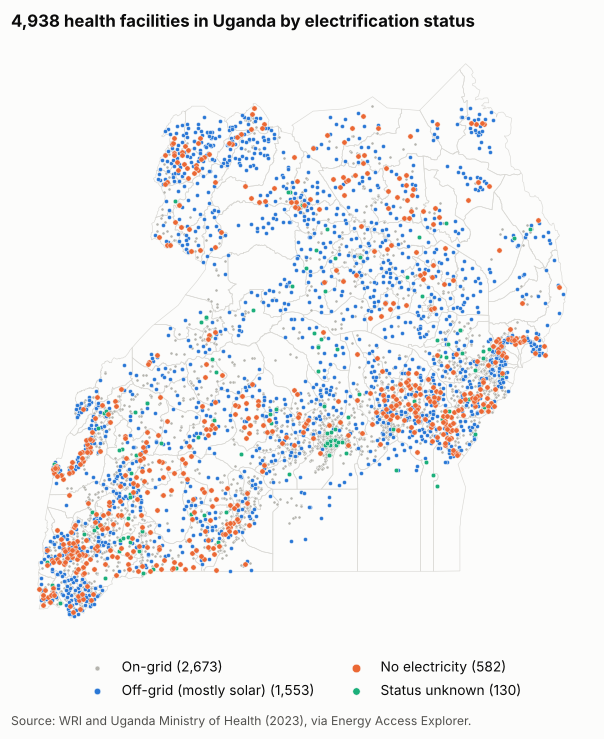

In [10]:
fig, ax = plt.subplots(figsize=(7.2, 7.2))
districts.boundary.plot(ax=ax, color=GRID, linewidth=0.4)
fac3857 = fac.to_crs(3857)
styles = [("On-grid", NEUTRAL, 4, "On-grid"), ("Off-grid", BLUE, 7, "Off-grid (mostly solar)"),
          ("No", ORANGE, 12, "No electricity"), ("Data unavailable", AQUA, 9, "Status unknown")]
for status, colour, size, label in styles:
    sub = fac3857[fac3857["ELECTRIFIC"] == status]
    ax.scatter(sub.geometry.x, sub.geometry.y, s=size, c=colour, edgecolors=SURFACE, linewidths=0.3,
               label=f"{label} ({len(sub):,})", zorder=3 if status == "No" else 2)
ax.set_axis_off()
ax.set_title(f"{len(fac):,} health facilities in Uganda by electrification status", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, fontsize=9, markerscale=1.6)
ax.text(0, -0.13, "Source: WRI and Uganda Ministry of Health (2023), via Energy Access Explorer.",
        transform=ax.transAxes, fontsize=8, color=INK2)
savefig(fig, "fig1_facilities_by_status")
plt.show()

**Takeaway:** two out of three facilities with no power are within 1 km of a line. The gap is mostly connections,
not grid reach, and that shapes both the filters and the plan.

## 3. Method

I rebuilt EAE's index in Python from the web tool's own code, so I could test many settings quickly. Each layer
becomes a 0-1 score per 1 km cell; scores are weighted and added; each district is then scored on its totals
(people summed, facilities counted, wealth and grid distance averaged) and split into five classes.

**Index:** the Assistance Need Index. Public money should go where need is high, people are poor and the grid is
far. Demand, Supply and Energy Access Potential are kept for comparison.

In [11]:
FILTER_TYPES = {"key-delta", "exclusion-buffer", "inclusion-buffer"}
EAE_INDEXES = {"eai": ["demand", "supply"], "demand": ["demand"], "supply": ["supply"], "ani": ["demand", "supply"]}
INDEX_NAMES = {"demand": "Demand Index", "supply": "Supply Index", "eai": "Energy Access Potential",
               "ani": "Assistance Need Index"}

def make_layers(settings=EAE_LAYERS):
    layers = []
    for key, s in settings.items():
        ds = find_dataset(key, s.get("dataset"))
        cat = merged_category(ds)
        default = cat.get("domain_init") or cat["domain"]
        rng = s["range"] if s["range"] is not None else (default["min"], default["max"])
        layers.append({"key": key, "label": s["label"], "weight": s["weight"], "range": tuple(rng),
                       "analysis": cat["analysis"], "index": cat["analysis"].get("index"),
                       "is_points": (cat.get("vectors") or {}).get("shape_type") == "points", **RASTERS[key]})
    return layers

def index_cfg(layer, index):
    return next((c for c in layer["analysis"].get("indexes") or [] if c["index"] == index), None)

def scale_of(layer, index):
    c = index_cfg(layer, index)
    return c["scale"] if c else None

def cell_scores(layer, index):
    """ds.js analysis_fn(): raster values -> score in [0, 1]; <0 or >1 means clipped; NaN means nodata."""
    x, (lo, hi), c = layer["near"], layer["range"], index_cfg(layer, index)
    if c is None:                                   # layer not part of this index: acts as a range filter
        s = np.where((x >= lo) & (x <= hi), 1.0, -1.0)
    elif c["scale"] == "exclusion-buffer":
        s = np.where((x < lo) | (x > hi), 1.0, -1.0)
    elif c["scale"] == "inclusion-buffer":
        s = np.where((x >= lo) & (x <= hi), 1.0, -1.0)
    elif c["scale"] == "intervals":                 # d3.scaleQuantile over the interval list -> 0, .25, .5, .75, 1
        thresholds = np.quantile(np.sort(layer["analysis"]["intervals"]), [0.2, 0.4, 0.6, 0.8])
        q = np.array([0, 0.25, 0.5, 0.75, 1.0])[np.searchsorted(thresholds, x, side="right")]
        s = np.where((x >= lo) & (x <= hi), q, -1.0)
    elif lo == hi:
        s = np.where(x == lo, 1.0, -1.0)
    else:                                           # linear, inverted where "closer is better"
        r0, r1 = (1.0, 0.0) if c.get("invert") else (0.0, 1.0)
        s = r0 + (x - lo) / (hi - lo) * (r1 - r0)
        if layer["analysis"].get("clamp"):
            s = np.clip(s, min(r0, r1), max(r0, r1))
    s = s.astype(float)
    s[x == layer["nodata"]] = np.nan
    return s

def weights_for(index, layers):
    """area-scores.js weights_for()."""
    singles = {i: 0 for i, parts in EAE_INDEXES.items() if len(parts) < 2}
    for L in layers:
        if scale_of(L, index) not in FILTER_TYPES and L["index"]:
            singles[L["index"]] += L["weight"]
    singles = {k: v for k, v in singles.items() if v}
    out = {}
    for L in layers:
        if scale_of(L, index) in FILTER_TYPES or not L["index"]:
            out[L["key"]] = 0.0
        elif index == "ani":
            out[L["key"]] = L["weight"] / sum(singles.values())
        else:
            out[L["key"]] = L["weight"] / (singles[L["index"]] * len(singles))
    return out

def run_index(layers, index):
    """analysis.js run(): weighted sum of cell scores, rescaled to [0, 1]; -1 = not analysed."""
    w = weights_for(index, layers)
    total, bad = np.zeros(N), np.zeros(N, dtype=bool)
    for L in layers:
        s = cell_scores(L, index)
        bad |= np.isnan(s) | (s < 0) | (s > 1)
        total += w[L["key"]] * np.nan_to_num(s)
    out = np.full(N, -1.0)
    ok = ~bad
    lo, hi = total[ok].min(), total[ok].max()
    out[ok] = (total[ok] - lo) / (hi - lo) if hi > lo else 0.0
    return out

def jenks_breaks(values, k=5):
    """area-scores.js jenks_breaks(): natural-breaks class edges (k + 1 edges)."""
    data = np.sort(np.asarray([v for v in values if np.isfinite(v)], float))
    n = len(data)
    if n < k or len(np.unique(data)) < k:
        return None
    cs, cs2 = np.concatenate([[0], np.cumsum(data)]), np.concatenate([[0], np.cumsum(data ** 2)])
    ssd = lambda a, b: (cs2[b + 1] - cs2[a]) - (cs[b + 1] - cs[a]) ** 2 / (b - a + 1)
    best = np.full((n + 1, k + 1), np.inf)
    start = np.zeros((n + 1, k + 1), dtype=int)
    for l in range(1, n + 1):
        best[l, 1], start[l, 1] = ssd(0, l - 1), 1
    for kk in range(2, k + 1):
        for l in range(kk, n + 1):
            for m in range(kk, l + 1):
                v = best[m - 1, kk - 1] + ssd(m - 1, l - 1)
                if v < best[l, kk]:
                    best[l, kk], start[l, kk] = v, m
    edges = [None] * (k + 1)
    edges[0], edges[k], l = data[0], data[n - 1], n
    for kk in range(k, 1, -1):
        m = start[l, kk]
        edges[kk - 1], l = data[m - 1], m - 1
    return edges

def bucket(value, edges):
    i = 0
    for e in range(1, len(edges) - 1):
        if edges[e] <= value:
            i = e
    return CLASS_LABELS[i]

FACILITY_PIXELS = {"health": fac["pix"].to_numpy()}

def district_scores(layers, index, cells=None, point_pixels=None, classes=True):
    """analysis.js compute_result_scores() with the 'layer_totals' strategy (EAE's district ranking)."""
    cells = run_index(layers, index) if cells is None else cells
    point_pixels = point_pixels or FACILITY_PIXELS
    divm = np.where((cells > 0) & (DISTRICT_RASTER >= 0), DISTRICT_RASTER, -1)
    ids = np.unique(divm[divm >= 0])
    w = weights_for(index, layers)
    totals, shares = {}, {}
    raw, wsum = pd.Series(0.0, index=ids), 0.0
    for L in layers:
        if L["is_points"]:
            a = divm[point_pixels[L["key"]][point_pixels[L["key"]] >= 0]]
            vals = pd.Series(np.bincount(a[a >= 0], minlength=N_DIV)[ids], index=ids, dtype=float)
        else:
            agg = L["analysis"].get("aggregation") or "AVG"
            band = L["sum"] if agg == "SUM" else L["avg"]
            ok = (divm >= 0) & (band != L["nodata"])
            g = pd.Series(band[ok]).groupby(divm[ok])
            vals = (g.sum() if agg == "SUM" else g.mean()).reindex(ids)
            if agg == "SUM":
                vals = vals.fillna(0.0)
        totals[L["key"]] = vals
        v = vals[np.isfinite(vals)]
        if not w[L["key"]] > 0 or v.empty or not (v.max() - v.min()) > 0:
            continue
        share = (v - v.min()) / (v.max() - v.min())
        if (index_cfg(L, index) or {}).get("invert") and not L["is_points"]:
            share = 1 - share
        wsum += w[L["key"]]
        shares[L["key"]] = (w[L["key"]] * share).reindex(ids).fillna(0.0)
        raw = raw.add(shares[L["key"]], fill_value=0.0)
    raw = raw / wsum
    score = 0.01 + 0.99 * (raw - raw.min()) / (raw.max() - raw.min())
    out = pd.DataFrame({"district": [DISTRICT_NAME[i] for i in ids], "score": score.values}, index=ids)
    for key, s in shares.items():
        out[f"share_{key}"] = s / wsum                  # contribution to the raw score (sums to raw)
    for key, v in totals.items():
        out[f"total_{key}"] = v
    if classes:
        edges = jenks_breaks(out["score"].values)
        out["class"] = [bucket(s, edges) for s in out["score"]]
    out = out.sort_values("score", ascending=False)
    out.insert(0, "rank", np.arange(1, len(out) + 1))
    return out

In [12]:
LAYERS = make_layers()
settings_rows = []
for L in LAYERS:
    side = (L["index"] or "filter").capitalize()
    direction = {}
    for idx in ["demand", "supply", "eai", "ani"]:
        c = index_cfg(L, idx)
        direction[idx] = ("filter only" if c is None else
                          "intervals (more = higher)" if c["scale"] == "intervals" else
                          "lower value = higher score" if c.get("invert") else "higher value = higher score")
    cat = merged_category(find_dataset(L["key"], EAE_LAYERS[L["key"]].get("dataset")))
    settings_rows.append({
        "side": side, "EAE layer": L["label"], "EAE path": " > ".join(cat["controls"]["path"]),
        "range (slider)": f"{L['range'][0]:g} to {L['range'][1]:g}" + (" km" if L["key"] in ("health", "distribution") else ""),
        "weight (1-5)": L["weight"], "in the ANI": direction["ani"],
        "district total": "count of facilities" if L["is_points"] else (L["analysis"].get("aggregation") or "AVG").lower(),
        "why": EAE_LAYERS[L["key"]]["why"]})
eae_settings = pd.DataFrame(settings_rows)
eae_settings.to_csv(TAB_DIR / "eae_settings.csv", index=False)

# save the settings for tools/eae_check.js
VAL_DIR = Path("outputs/validation")
VAL_DIR.mkdir(parents=True, exist_ok=True)
(VAL_DIR / "eae_check_settings.json").write_text(json.dumps({
    "geography": GEO["id"], "index": MAIN_INDEX,
    "divtier": [d["name"] for d in GEO["configuration"]["divisions"]].index("District"),
    "datasets": [{"id": find_dataset(L["key"], EAE_LAYERS[L["key"]].get("dataset")).get("name") or L["key"],
                  "weight": L["weight"], "min": L["range"][0], "max": L["range"][1]} for L in LAYERS],
}, indent=1))
print("Index:", INDEX_NAMES[MAIN_INDEX], "| admin level: district | weights:",
      {k: round(v, 3) for k, v in weights_for(MAIN_INDEX, LAYERS).items()})
eae_settings

Index: Assistance Need Index | admin level: district | weights: {'population-density': 0.25, 'relative-wealth-index': 0.25, 'health': 0.312, 'distribution': 0.188}


,side,EAE layer,EAE path,range (slider),weight (1-5),in the ANI,district total,why
0,Demand,Population,demand > demographics,0 to 1500,4,intervals (more = higher),sum,Number of people who can use the facilities. I...
1,Demand,Relative Wealth Index,demand > demographics,-2 to 2,4,lower value = higher score,avg,Proxy for poverty. In the ANI poorer areas sco...
2,Demand,Health facilities,demand > productive-uses,0 to 5 km,5,lower value = higher score,count of facilities,"The main layer for a health programme, so it g..."
3,Supply,Distribution lines,supply > infrastructure,0 to 700 km,3,higher value = higher score,avg,Distance to the 11/33 kV grid. In the ANI area...


Layers I left out, and why:

In [13]:
ghi_vals = RASTERS["ghi"]["near"][RASTERS["ghi"]["near"] != RASTERS["ghi"]["nodata"]]
ntl_vals = RASTERS["nighttime-lights"]["near"][RASTERS["nighttime-lights"]["near"] != RASTERS["nighttime-lights"]["nodata"]]
excluded = pd.DataFrame([
    {"EAE layer": "Global Horizontal Irradiation (GHI)",
     "reason": f"Solar resource is high almost everywhere (5th-95th percentile {np.percentile(ghi_vals, 5):,.0f}-"
               f"{np.percentile(ghi_vals, 95):,.0f} kWh/m2/yr). Also, in the ANI EAE scores low GHI as higher need, "
               "which does not make sense for a solar programme. I only use GHI to check the funded sites."},
    {"EAE layer": "Nighttime lights",
     "reason": f"{(ntl_vals <= 0.09).mean():.0%} of cells are dark, so it does not separate rural areas."},
    {"EAE layer": "Planned distribution lines",
     "reason": "Plans can be delayed, and the programme is for facilities that need power now."},
    {"EAE layer": "Schools, financial services, mini-grids",
     "reason": "Not related to health, they would dilute the ranking."},
    {"EAE layer": "Protected areas",
     "reason": "The facilities already exist and rooftop systems do not need extra land."},
])
excluded.to_csv(TAB_DIR / "eae_layers_excluded.csv", index=False)
excluded

,EAE layer,reason
0,Global Horizontal Irradiation (GHI),Solar resource is high almost everywhere (5th-...
1,Nighttime lights,"96% of cells are dark, so it does not separate..."
2,Planned distribution lines,"Plans can be delayed, and the programme is for..."
3,"Schools, financial services, mini-grids","Not related to health, they would dilute the r..."
4,Protected areas,The facilities already exist and rooftop syste...


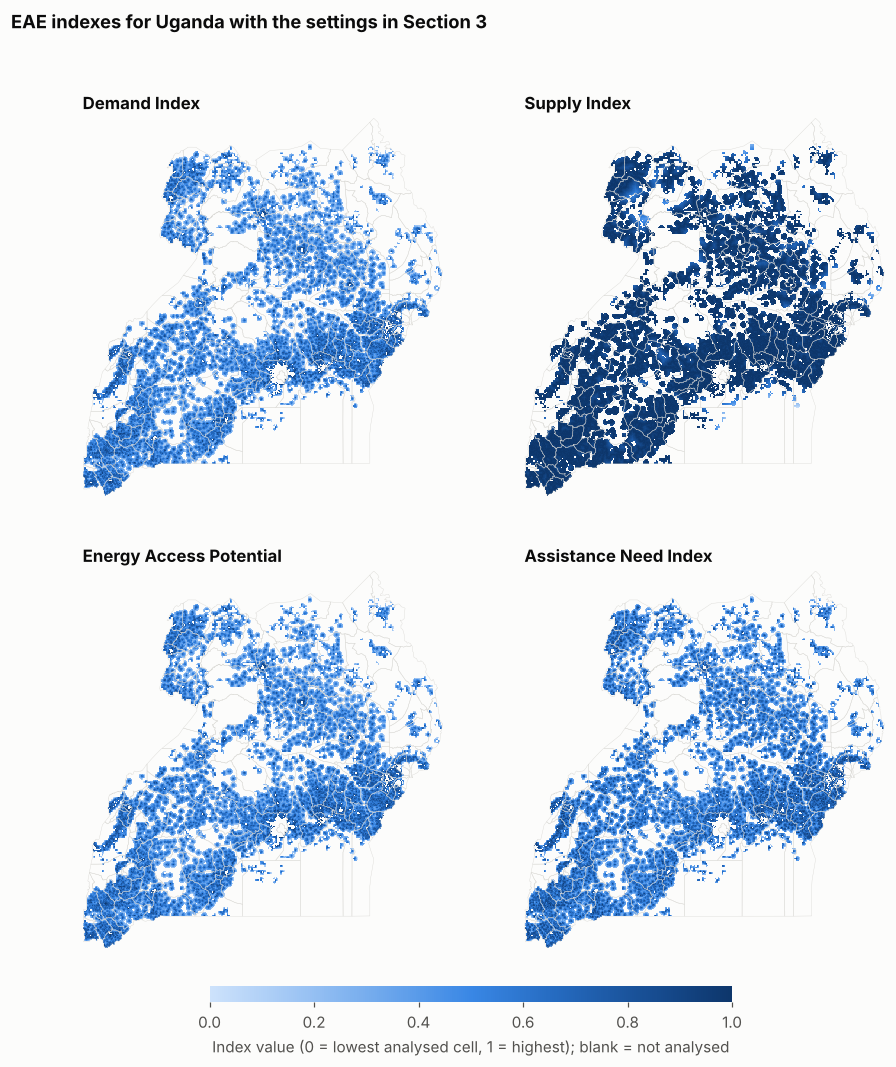

In [14]:
INDEX_CELLS = {idx: run_index(LAYERS, idx) for idx in ["demand", "supply", "eai", "ani"]}
fig, axes = plt.subplots(2, 2, figsize=(9.5, 9.8))
for ax, idx in zip(axes.ravel(), ["demand", "supply", "eai", "ani"]):
    img = np.ma.masked_less(INDEX_CELLS[idx].reshape(H, W), 0)
    im = ax.imshow(img, cmap=SEQ, vmin=0, vmax=1, extent=EXTENT, interpolation="nearest")
    districts.boundary.plot(ax=ax, color=GRID, linewidth=0.25)
    ax.set_title(INDEX_NAMES[idx], loc="left")
    ax.set_axis_off()
cax = fig.add_axes([0.25, 0.06, 0.5, 0.015])
cb = fig.colorbar(im, cax=cax, orientation="horizontal")
cb.set_label("Index value (0 = lowest analysed cell, 1 = highest); blank = not analysed", color=INK2)
cb.outline.set_visible(False)
fig.suptitle("EAE indexes for Uganda with the settings in Section 3", x=0.06, ha="left", fontweight="bold")
savefig(fig, "fig2_eae_indexes")
plt.show()

**Check:** `tools/eae_check.js` runs the live EAE tool with the same settings and saves a screenshot. If my version
is right, every district should match.

,value
EAE settings used by the tool,"distribution-lines w3 [0, 700], health w5 [0, ..."
districts scored (tool / notebook),146 / 146
analysed 1 km cells (tool / notebook),"125,210 / 125,209"
largest district score difference,0.0008
districts in the same class,100%
same rank (top 20 / all),100% / 99%


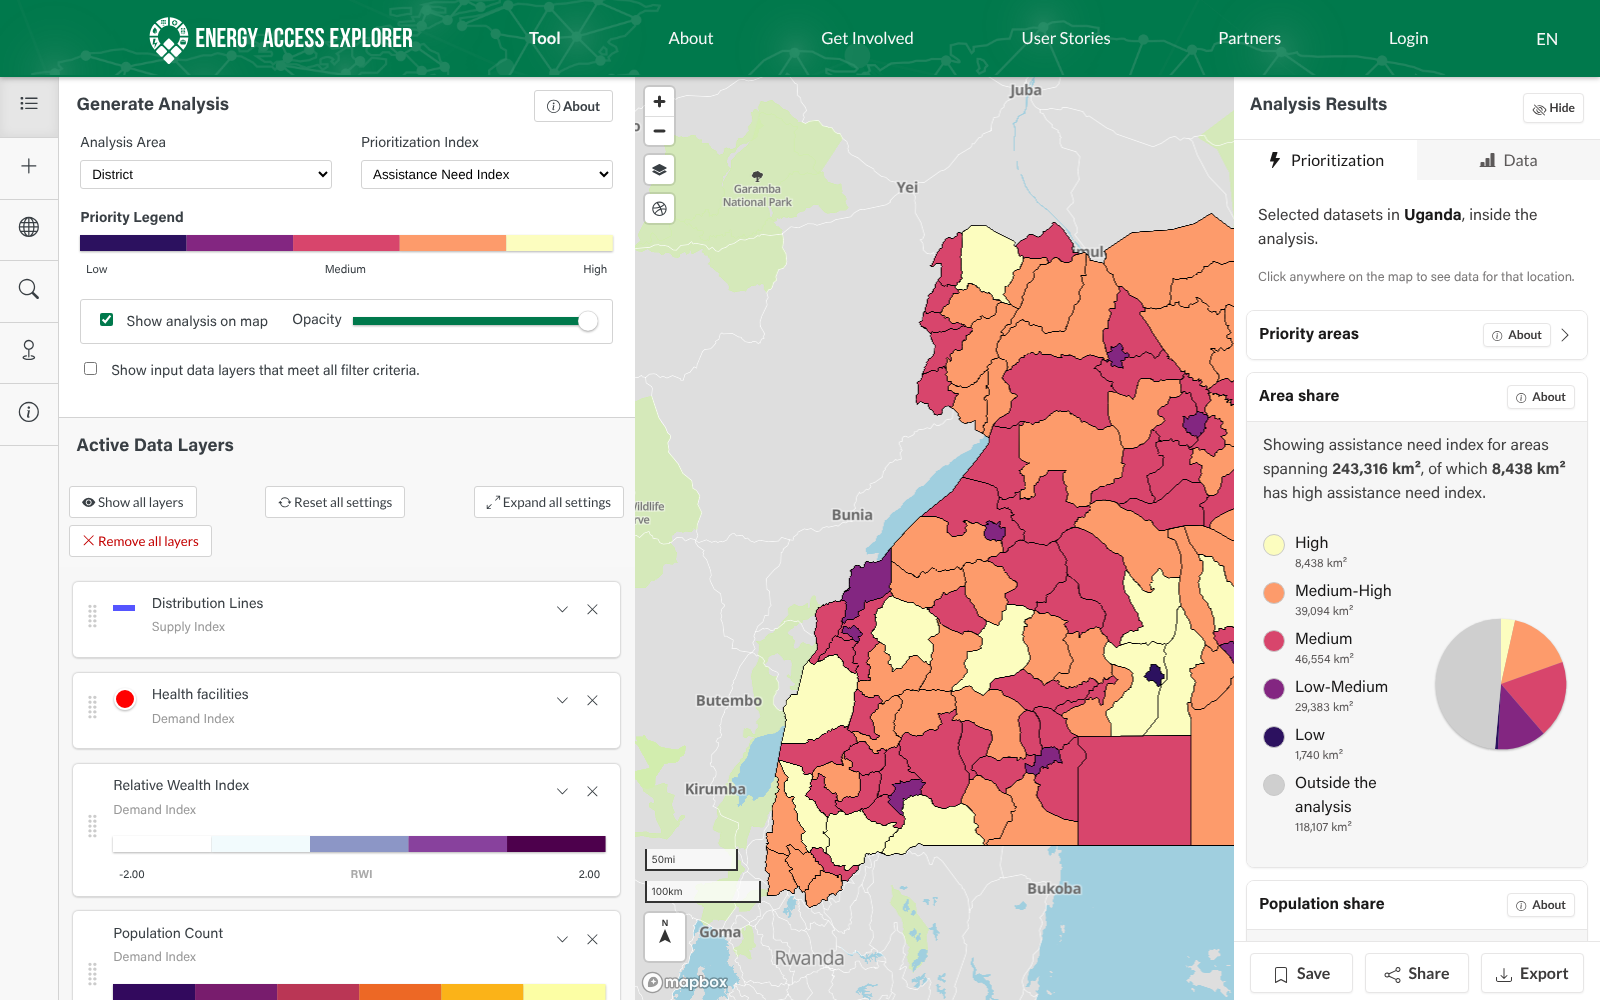

In [15]:
tool_file = Path("outputs/validation/eae_tool_ani_districts.json")
if tool_file.exists():
    tool = json.loads(tool_file.read_text())
    mine = district_scores(LAYERS, MAIN_INDEX, cells=INDEX_CELLS[MAIN_INDEX])
    t = pd.DataFrame(tool["areas"]).T
    t.index = t.index.astype(int)
    both = mine[["district", "score", "class"]].join(
        t.rename(columns={"score": "tool_score", "bucket": "tool_class"}).astype({"tool_score": float}))
    both["tool_rank"] = both["tool_score"].rank(ascending=False, method="first").astype(int)
    validation = pd.Series({
        "EAE settings used by the tool": ", ".join(f"{d['id']} w{d['weight']} [{d['_domain']['min']}, {d['_domain']['max']}]"
                                                   for d in tool["active"] if d["index"]),
        "districts scored (tool / notebook)": f"{len(t)} / {len(mine)}",
        "analysed 1 km cells (tool / notebook)": f"{tool['analysed_cells']:,} / {(INDEX_CELLS[MAIN_INDEX] > 0).sum():,}",
        "largest district score difference": f"{(both['score'] - both['tool_score']).abs().max():.4f}",
        "districts in the same class": f"{(both['class'] == both['tool_class']).mean():.0%}",
        "same rank (top 20 / all)": f"{(both['tool_rank'].head(20).values == np.arange(1, 21)).mean():.0%} / "
                                    f"{(both['tool_rank'].values == np.arange(1, len(both) + 1)).mean():.0%}",
    }, name="value")
    validation.to_csv(TAB_DIR / "validation_vs_eae_tool.csv")
    display(validation.to_frame())
    shot = FIG_DIR / "fig0_eae_tool_screenshot.png"
    if shot.exists():
        from IPython.display import Image as IPImage
        display(IPImage(filename=str(shot), width=900))
else:
    print("No saved EAE tool output; run tools/eae_check.js to create it.")

## 4. Priority districts

Towns are filtered out (population 0-1,500 per km²): they are already on the grid, and leaving them in puts Kampala
2nd with no unelectrified facility. EAE counts all facilities, not only those without power, so I show the
unelectrified counts next to the score.

In [16]:
ranking = district_scores(LAYERS, MAIN_INDEX)

gov = fac["OWNERSHIP"].isin(ELIGIBLE_OWNERSHIP)
fac["group"] = np.select(
    [fac["ELECTRIFIC"].eq("No"), fac["ELECTRIFIC"].eq("Off-grid") & fac["LEVEL"].isin(UPGRADE_LEVELS)],
    ["Unelectrified", "Under-electrified"], default="")
per_district = fac.groupby("district_id").agg(
    facilities=("FACILITY_N", "size"),
    unelectrified=("ELECTRIFIC", lambda s: (s == "No").sum()),
    unelectrified_govt=("group", lambda s: ((s == "Unelectrified") & gov.loc[s.index]).sum()),
    under_electrified_govt=("group", lambda s: ((s == "Under-electrified") & gov.loc[s.index]).sum()),
    status_unknown=("ELECTRIFIC", lambda s: (s == "Data unavailable").sum()),
)
target_mask = fac["group"].ne("") & gov
per_district["target_catchment_pop"] = fac[target_mask].groupby("district_id")["catchment_pop"].sum()
per_district["target_median_km_to_line"] = fac[target_mask].groupby("district_id")["dist_line_km"].median()
ranking = ranking.join(per_district, how="left").fillna({c: 0 for c in per_district.columns if c != "target_median_km_to_line"})

LABEL = {L["key"]: L["label"] for L in LAYERS}
SHORT = {"population-density": "people", "relative-wealth-index": "poverty", "health": "facility count",
         "distribution": "distance from grid"}

# main drivers = the two layers on which a district places highest among all districts
places = pd.DataFrame({
    "health": ranking["total_health"].rank(ascending=False, method="min"),
    "population-density": ranking["total_population-density"].rank(ascending=False, method="min"),
    "relative-wealth-index": ranking["total_relative-wealth-index"].rank(ascending=True, method="min"),
    "distribution": ranking["total_distribution"].rank(ascending=False, method="min"),
})
ranking["main drivers"] = [", ".join(f"{SHORT[k]} (#{int(r[k])})" for k in r.sort_values().index[:2])
                           for _, r in places.iterrows()]
ranking["population_analysed"] = ranking["total_population-density"]
ranking["mean_rwi"] = ranking["total_relative-wealth-index"]
ranking["mean_km_to_line"] = ranking["total_distribution"]
ranking["facilities_counted"] = ranking["total_health"]
cols = ["rank", "district", "score", "class", "main drivers", "population_analysed", "mean_rwi", "mean_km_to_line",
        "facilities_counted", "unelectrified", "unelectrified_govt", "under_electrified_govt", "target_catchment_pop"]
ranking[cols].to_csv(TAB_DIR / "district_ranking_ani.csv", index=False)
print(ranking["class"].value_counts().reindex(CLASS_LABELS[::-1]).to_string())
ranking[cols].head(15).style.format({"score": "{:.0%}", "population_analysed": "{:,.0f}", "mean_rwi": "{:.2f}",
                                     "mean_km_to_line": "{:.1f}", "facilities_counted": "{:.0f}",
                                     "target_catchment_pop": "{:,.0f}", "unelectrified": "{:.0f}",
                                     "unelectrified_govt": "{:.0f}", "under_electrified_govt": "{:.0f}"})

class
High           14
Medium-High    46
Medium         70
Low-Medium     15
Low             1


,rank,district,score,class,main drivers,population_analysed,mean_rwi,mean_km_to_line,facilities_counted,unelectrified,unelectrified_govt,under_electrified_govt,target_catchment_pop
60,1,Kasese,100%,High,"facility count (#2), people (#2)","686,141",-0.20,2.1,78,29,29,8,"121,320"
40,2,Isingiro,93%,High,"facility count (#4), people (#4)","622,579",-0.22,1.9,70,17,17,0,"85,532"
142,3,Tororo,91%,High,"facility count (#3), people (#5)","616,285",-0.13,0.8,73,23,22,2,"71,193"
133,4,Rukungiri,84%,High,"facility count (#1), people (#24)","357,938",-0.21,0.9,79,28,26,2,"63,116"
54,5,Kamuli,82%,High,"facility count (#6), people (#6)","593,497",-0.15,0.9,56,7,7,0,"21,098"
88,6,Luweero,82%,High,"facility count (#5), people (#11)","522,902",-0.14,1.3,61,1,1,1,"14,056"
108,7,Mukono,79%,High,"people (#7), facility count (#10)","565,140",-0.04,2.9,50,4,4,1,"14,881"
107,8,Mubende,79%,High,"people (#9), facility count (#14)","545,103",-0.29,2.1,44,8,8,1,"57,948"
120,9,Ntungamo,79%,High,"facility count (#7), people (#8)","558,308",-0.11,1.2,53,13,13,1,"113,309"
143,10,Wakiso,76%,High,"people (#1), facility count (#22)","737,848",0.06,1.4,38,7,7,0,"18,128"


In [17]:
# what drives the top five: where each district stands among all 146 on each driver (1 = highest)
n_d = len(ranking)
place = pd.DataFrame({
    "facilities counted": ranking["facilities_counted"].rank(ascending=False, method="min"),
    "people (analysed area)": ranking["population_analysed"].rank(ascending=False, method="min"),
    "poverty (lowest RWI)": ranking["mean_rwi"].rank(ascending=True, method="min"),
    "distance from grid": ranking["mean_km_to_line"].rank(ascending=False, method="min"),
    "unelectrified (govt)": ranking["unelectrified_govt"].rank(ascending=False, method="min"),
}).astype(int)
place.insert(0, "district", ranking["district"])
top5_place = place.head(5).set_index("district")
top5_place.to_csv(TAB_DIR / "top5_driver_places.csv")
for d, r in top5_place.iterrows():
    print(f"{d}: facilities #{r['facilities counted']}, people #{r['people (analysed area)']}, "
          f"poverty #{r['poverty (lowest RWI)']}, grid distance #{r['distance from grid']}, "
          f"unelectrified #{r['unelectrified (govt)']} of {n_d}")
top5_place

Kasese: facilities #2, people #2, poverty #74, grid distance #52, unelectrified #1 of 146
Isingiro: facilities #4, people #4, poverty #72, grid distance #64, unelectrified #5 of 146
Tororo: facilities #3, people #5, poverty #98, grid distance #133, unelectrified #3 of 146
Rukungiri: facilities #1, people #24, poverty #73, grid distance #129, unelectrified #2 of 146
Kamuli: facilities #6, people #6, poverty #91, grid distance #125, unelectrified #23 of 146


,facilities counted,people (analysed area),poverty (lowest RWI),distance from grid,unelectrified (govt)
district,,,,,
Kasese,2,2,74,52,1
Isingiro,4,4,72,64,5
Tororo,3,5,98,133,3
Rukungiri,1,24,73,129,2
Kamuli,6,6,91,125,23


**What drives the top five: size.** They have the most facilities (1st-6th) and among the most people (2nd-24th),
but are mid-table on poverty and close to the grid. Need agrees for three of them: Kasese, Rukungiri and Tororo
have the most unelectrified facilities in Uganda. Kamuli (7) is the weak one; counting only unelectrified
facilities swaps it for Bugiri.

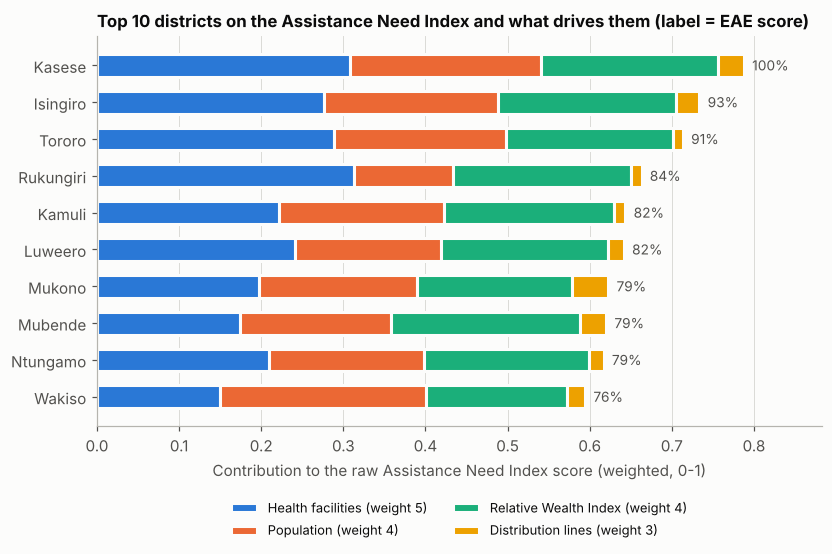

In [18]:
# what drives the top 10: contribution of each layer to the raw ANI score
top10 = ranking.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 4.6))
left = np.zeros(len(top10))
for key, colour in zip(["health", "population-density", "relative-wealth-index", "distribution"],
                       [BLUE, ORANGE, AQUA, YELLOW]):
    vals = top10[f"share_{key}"].to_numpy()
    ax.barh(top10["district"], vals, left=left, color=colour, height=0.62, edgecolor=SURFACE, linewidth=2,
            label=f"{LABEL[key]} (weight {EAE_LAYERS[key]['weight']})")
    left += vals
for y, (tot, sc) in enumerate(zip(left, top10["score"])):
    ax.text(tot + 0.01, y, f"{sc:.0%}", va="center", fontsize=9, color=INK2)
ax.set_xlabel("Contribution to the raw Assistance Need Index score (weighted, 0-1)")
ax.set_xlim(0, max(left) * 1.12)
ax.xaxis.grid(True)
ax.set_axisbelow(True)
ax.set_title("Top 10 districts on the Assistance Need Index and what drives them (label = EAE score)", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, fontsize=8.5)
savefig(fig, "fig3_top_district_drivers")
plt.show()

In [19]:
# top 10 for each of the four indexes
ALL_SCORES = {idx: district_scores(LAYERS, idx, cells=INDEX_CELLS[idx]) for idx in ["demand", "supply", "eai", "ani"]}
compare = pd.DataFrame({INDEX_NAMES[i]: ALL_SCORES[i]["district"].head(10).to_list() for i in ALL_SCORES},
                       index=pd.RangeIndex(1, 11, name="rank"))
compare.to_csv(TAB_DIR / "index_comparison_top10.csv")
ani_top10 = set(compare[INDEX_NAMES["ani"]])
print({INDEX_NAMES[i]: len(ani_top10 & set(compare[INDEX_NAMES[i]])) for i in ALL_SCORES}, "of the ANI top 10 shared")
compare

{'Demand Index': 3, 'Supply Index': 8, 'Energy Access Potential': 8, 'Assistance Need Index': 10} of the ANI top 10 shared


,Demand Index,Supply Index,Energy Access Potential,Assistance Need Index
rank,,,,
1,Amudat,Tororo,Tororo,Kasese
2,Buvuma,Kasese,Kasese,Isingiro
3,Obongi,Rukungiri,Rukungiri,Tororo
4,Kasese,Kamuli,Kamuli,Rukungiri
5,Kalangala,Isingiro,Isingiro,Kamuli
6,Terego,Wakiso,Wakiso,Luweero
7,Lamwo,Luweero,Luweero,Mukono
8,Isingiro,Ntungamo,Ntungamo,Mubende
9,Mukono,Buikwe,Buikwe,Ntungamo


In [20]:
# robustness 1: changing the criteria
def with_settings(**changes):
    s = json.loads(json.dumps(EAE_LAYERS))
    for key, upd in changes.items():
        if upd is None:
            s.pop(key)
        else:
            s[key].update(upd)
    return make_layers(s)

unel_pixels = {"health": fac.loc[fac["ELECTRIFIC"] == "No", "pix"].to_numpy()}
VARIANTS = {
    "Baseline (Section 3 settings)": (LAYERS, None),
    "EAE default population range (towns kept)": (with_settings(**{"population-density": {"range": None}}), None),
    "Health facilities within 10 km": (with_settings(health={"range": (0, 10)}), None),
    "Without Relative Wealth Index": (with_settings(**{"relative-wealth-index": None}), None),
    "Only >2 km from lines (lecture filter)": (with_settings(distribution={"range": (2, 700)}), None),
    "Equal weights (all 3)": (with_settings(**{k: {"weight": 3} for k in EAE_LAYERS}), None),
    "Count unelectrified facilities only*": (LAYERS, unel_pixels),
    "Add solar resource (GHI, weight 3)": (make_layers({**EAE_LAYERS, "ghi": {
        "label": "Solar resource (GHI)", "weight": 3, "range": None, "why": ""}}), None),
}
base_top5, base_top10 = set(ranking["district"].head(5)), set(ranking["district"].head(10))
var_rows, var_tops = [], {}
for name, (lay, pts) in VARIANTS.items():
    r = district_scores(lay, MAIN_INDEX, point_pixels=pts, classes=False)
    var_tops[name] = r["district"].head(10).to_list()
    var_rows.append({"variant": name, "top 5": ", ".join(r["district"].head(5)),
                     "baseline top 5 kept in top 10": len(base_top5 & set(r["district"].head(10))),
                     "top 10 overlap with baseline": len(base_top10 & set(r["district"].head(10)))})
variants = pd.DataFrame(var_rows)
variants.to_csv(TAB_DIR / "robustness_variants.csv", index=False)
print("* cannot be done in the web tool, only here")
variants

* cannot be done in the web tool, only here


,variant,top 5,baseline top 5 kept in top 10,top 10 overlap with baseline
0,Baseline (Section 3 settings),"Kasese, Isingiro, Tororo, Rukungiri, Kamuli",5,10
1,EAE default population range (towns kept),"Wakiso, Kampala, Amudat, Buvuma, Lamwo",1,2
2,Health facilities within 10 km,"Kasese, Isingiro, Tororo, Rukungiri, Luweero",5,10
3,Without Relative Wealth Index,"Kasese, Isingiro, Tororo, Mukono, Rukungiri",5,9
4,Only >2 km from lines (lecture filter),"Kasese, Terego, Isingiro, Buvuma, Adjumani",2,3
5,Equal weights (all 3),"Kasese, Isingiro, Tororo, Rukungiri, Kamuli",5,9
6,Count unelectrified facilities only*,"Kasese, Tororo, Rukungiri, Isingiro, Bugiri",4,7
7,"Add solar resource (GHI, weight 3)","Kasese, Isingiro, Rukungiri, Tororo, Ntungamo",5,10


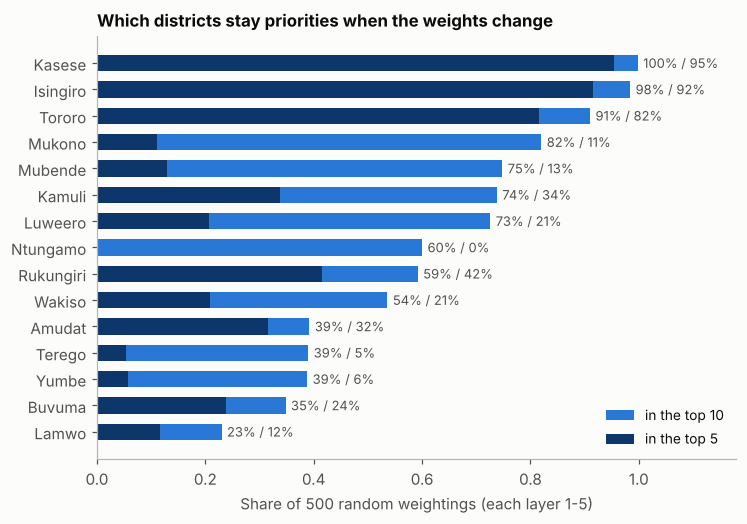

,share of draws in top 5,share of draws in top 10,baseline rank
district,,,
Kasese,0.95,1.00,1
Isingiro,0.92,0.98,2
Tororo,0.82,0.91,3
Mukono,0.11,0.82,7
Mubende,0.13,0.75,8
Kamuli,0.34,0.74,5
Luweero,0.21,0.73,6
Ntungamo,0.00,0.60,9
Rukungiri,0.42,0.59,4


In [21]:
# robustness 2: random weights (1-5) for every layer
rng = np.random.default_rng(RNG_SEED)
in5, in10 = pd.Series(0, index=ranking["district"]), pd.Series(0, index=ranking["district"])
for _ in range(N_WEIGHT_DRAWS):
    lay = [dict(L, weight=int(rng.integers(1, 6))) for L in LAYERS]
    r = district_scores(lay, MAIN_INDEX, classes=False)
    in5[r["district"].head(5)] += 1
    in10[r["district"].head(10)] += 1
mc = pd.DataFrame({"share of draws in top 5": in5 / N_WEIGHT_DRAWS, "share of draws in top 10": in10 / N_WEIGHT_DRAWS,
                   "baseline rank": ranking.set_index("district")["rank"]}).sort_values(
    ["share of draws in top 10", "share of draws in top 5"], ascending=False)
mc.to_csv(TAB_DIR / "robustness_weights_montecarlo.csv")

show = mc.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(show.index, show["share of draws in top 10"], color=BLUE, height=0.62, label="in the top 10")
ax.barh(show.index, show["share of draws in top 5"], color="#0d366b", height=0.62, label="in the top 5")
for y, (v10, v5) in enumerate(zip(show["share of draws in top 10"], show["share of draws in top 5"])):
    ax.text(v10 + 0.01, y, f"{v10:.0%} / {v5:.0%}", va="center", fontsize=8.5, color=INK2)
ax.set_xlim(0, 1.18)
ax.set_xlabel(f"Share of {N_WEIGHT_DRAWS} random weightings (each layer 1-5)")
ax.set_title("Which districts stay priorities when the weights change", loc="left")
ax.legend(loc="lower right", fontsize=9)
savefig(fig, "fig4_robustness_weights")
plt.show()
mc.head(15)

**Takeaway:** Kasese, Isingiro and Tororo hold up under any weighting. The town filter and the >2 km grid filter
move the answer far more than the weights do.

## 5. Cost per facility

Stand-alone solar + battery, sized from each facility's modelled kWh/day:

- size = kWh/day / 2.78 (Energizing Health, Table 3)
- $3,609 per kWp installed, battery included (3 Ugandan health centres, 2022)
- +20% delivery, +17% maintenance reserve (5 years of O&M)

Eligible: government facilities with no power, plus off-grid HC IIIs/IVs, whose maternity and lab loads outgrow a
basic kit. Sanity check: an 8-bed HC III comes out at 9.6 kWp, the size of the real Ugandan systems.

In [22]:
def add_costs(df, mult=1.0):
    out = df.copy()
    out["kwp"] = out["kwh_day"] / COST["kwh_per_kwp_day"]
    out["capex"] = out["kwp"] * COST["usd_per_kwp"] * mult
    out["overhead"] = out["capex"] * COST["delivery_overhead"]
    out["reserve"] = out["capex"] * COST["om_share_per_year"] * COST["reserve_years"]
    out["total_cost"] = out["capex"] + out["overhead"] + out["reserve"]
    out["usd_per_person"] = out["total_cost"] / out["catchment_pop"]
    return out

district_info = ranking[["score", "class", "rank"]]          # indexed by EAE district id
eligible = fac[target_mask & (fac["kwh_day"] > 0) & (fac["catchment_pop"] > 0) & fac["district_id"].notna()].copy()
eligible = eligible.join(district_info, on="district_id")
eligible["class"] = eligible["class"].fillna("Not analysed")
eligible["score"] = eligible["score"].fillna(0.0)
eligible = add_costs(eligible)

unit_costs = (add_costs(archetypes.rename(columns={"median_catchment": "catchment_pop"}))
              [["LEVEL", "beds", "kwh_day", "kwp", "capex", "overhead", "reserve", "total_cost", "catchment_pop",
                "usd_per_person"]])
unit_costs.to_csv(TAB_DIR / "cost_per_facility_by_archetype.csv", index=False)
print(f"Eligible facilities: {len(eligible)} "
      f"({(eligible['group'] == 'Unelectrified').sum()} unelectrified, "
      f"{(eligible['group'] == 'Under-electrified').sum()} under-electrified); "
      f"cost to do them all: ${eligible['total_cost'].sum() / 1e6:,.1f} million")
for g, sub in eligible.groupby("group"):
    print(f"  {g}: {len(sub)} facilities, ${sub['total_cost'].sum() / 1e6:,.1f} M, "
          f"median ${sub['total_cost'].median():,.0f} per facility, {sub['catchment_pop'].sum():,.0f} people")
unit_costs.style.format({"kwh_day": "{:.1f}", "kwp": "{:.1f}", "capex": "${:,.0f}", "overhead": "${:,.0f}",
                         "reserve": "${:,.0f}", "total_cost": "${:,.0f}", "catchment_pop": "{:,.0f}",
                         "usd_per_person": "${:.2f}", "beds": "{:.0f}"})

Eligible facilities: 853 (529 unelectrified, 324 under-electrified); cost to do them all: $64.2 million
  Under-electrified: 324 facilities, $52.7 M, median $47,519 per facility, 1,869,617 people
  Unelectrified: 529 facilities, $11.5 M, median $14,824 per facility, 2,272,638 people


,LEVEL,beds,kwh_day,kwp,capex,overhead,reserve,total_cost,catchment_pop,usd_per_person
0,HC II,2,8.3,3.0,"$10,809","$2,162","$1,853","$14,824","2,229",$6.65
1,HC II,3,12.2,4.4,"$15,863","$3,173","$2,719","$21,755","7,718",$2.82
2,HC III,8,26.7,9.6,"$34,649","$6,930","$5,940","$47,519","2,727",$17.43
3,HC III,12,134.0,48.2,"$174,052","$34,810","$29,837","$238,700","7,268",$32.84
4,HC III,14,161.9,58.3,"$210,338","$42,068","$36,058","$288,464","9,152",$31.52
5,HC III,16,186.6,67.2,"$242,480","$48,496","$41,568","$332,544","10,824",$30.72
6,HC III,20,229.3,82.5,"$297,890","$59,578","$51,067","$408,535","13,596",$30.05
7,HC III,24,261.7,94.2,"$339,958","$67,992","$58,278","$466,228","18,698",$24.93
8,HC IV,25,295.7,106.5,"$384,169","$76,834","$65,858","$526,860","3,436",$153.34
9,HC IV,29,324.2,116.7,"$421,235","$84,247","$72,212","$577,693","21,927",$26.35


**Takeaway:** one large HC III costs as much as 13-19 small HC IIs, so *which* facilities matters as much as *where*.

## 6. Spending the US$1,000,000

Four plans, each funding facilities in order until the money runs out:

- **Need first:** districts in ANI order.
- **Value for money:** cheapest per person, anywhere.
- **High-need, cheapest first:** High-class districts only, cheapest first (ends up all HC IIs).
- **Recommended:** the same, but unpowered maternity wards (HC IIIs under $100k) first, because maternity care is
  where mothers and newborns die.

In [23]:
GROUP_RANK = {"Unelectrified": 0, "Under-electrified": 1}
CLASS_RANK = {c: i for i, c in enumerate(CLASS_LABELS[::-1])}

def is_maternity_gap(df):
    """unelectrified facility with a maternity ward that fits the budget"""
    return ((df["group"] == "Unelectrified") & df["LEVEL"].isin(MATERNITY_LEVELS)
            & (df["total_cost"] <= MATERNITY_COST_CAP))

def order_for(scenario, df):
    d = df.assign(group_rank=df["group"].map(GROUP_RANK), class_rank=df["class"].map(CLASS_RANK).fillna(9),
                  in_top=(~df["class"].isin(TOP_CLASSES)).astype(int))
    d["maternity_rank"] = np.where(is_maternity_gap(d), 0, d["group_rank"] + 1)
    if scenario == "Need first":
        return d.sort_values(["score", "group_rank", "usd_per_person"], ascending=[False, True, True])
    if scenario == "Value for money":
        return d.sort_values(["usd_per_person"])
    if scenario == "High-need, cheapest first":
        return d.sort_values(["in_top", "class_rank", "group_rank", "usd_per_person"])
    if scenario == "Recommended":
        return d.sort_values(["in_top", "class_rank", "maternity_rank", "usd_per_person"])
    raise ValueError(scenario)

def allocate(df, scenario, budget=BUDGET_USD):
    order = order_for(scenario, df)
    take, remaining = [], budget
    for i, c in zip(order.index, order["total_cost"]):
        if c <= remaining:
            take.append(i)
            remaining -= c
    return order.loc[take], remaining

def summarise(funded, remaining, df):
    return {"facilities funded": len(funded),
            "of which unelectrified": int((funded["group"] == "Unelectrified").sum()),
            "of which under-electrified": int((funded["group"] == "Under-electrified").sum()),
            "HC II / HC III / HC IV": "/".join(str(int((funded["LEVEL"] == l).sum())) for l in ["HC II", "HC III", "HC IV"]),
            "maternity wards powered": int(funded["LEVEL"].isin(MATERNITY_LEVELS).sum()),
            "people reached": funded["catchment_pop"].sum(),
            "US$ per person": (BUDGET_USD - remaining) / funded["catchment_pop"].sum(),
            "districts reached": funded["district"].nunique(),
            "funded in High-class districts": int(funded["class"].isin(TOP_CLASSES).sum()),
            "solar kWp": funded["kwp"].sum(), "kWh/day supplied": funded["kwh_day"].sum(),
            "equipment + installation": funded["capex"].sum(), "delivery overhead": funded["overhead"].sum(),
            "maintenance reserve": funded["reserve"].sum(), "unspent": remaining,
            "unelectrified (eligible) left unfunded": int((df["group"] == "Unelectrified").sum()
                                                          - (funded["group"] == "Unelectrified").sum())}

SCENARIOS = ["Need first", "Value for money", "High-need, cheapest first", "Recommended"]
PLANS = {s: allocate(eligible, s) for s in SCENARIOS}
scenario_summary = pd.DataFrame({s: summarise(f, r, eligible) for s, (f, r) in PLANS.items()})
scenario_summary.to_csv(TAB_DIR / "scenario_summary.csv")
for s in SCENARIOS:
    x = scenario_summary[s]
    print(f"{s + ':':28s}{x['facilities funded']} facilities ({x['maternity wards powered']} with maternity wards) "
          f"in {x['districts reached']} districts, {x['people reached']:,.0f} people at ${x['US$ per person']:.2f} "
          f"each; {x['funded in High-class districts']} in High-need districts")
hc2, rec = scenario_summary["High-need, cheapest first"], scenario_summary["Recommended"]
print(f"\nPowering {rec['maternity wards powered']} maternity wards first costs "
      f"{hc2['facilities funded'] - rec['facilities funded']} small health centres and "
      f"{hc2['people reached'] - rec['people reached']:,.0f} people "
      f"({1 - rec['people reached'] / hc2['people reached']:.0%} fewer) compared with funding HC IIs only.")
scenario_summary

Need first:                 47 facilities (7 with maternity wards) in 2 districts, 186,756 people at $5.33 each; 47 in High-need districts
Value for money:            47 facilities (0 with maternity wards) in 31 districts, 635,820 people at $1.56 each; 12 in High-need districts
High-need, cheapest first:  53 facilities (0 with maternity wards) in 13 districts, 384,013 people at $2.57 each; 53 in High-need districts
Recommended:                46 facilities (4 with maternity wards) in 13 districts, 347,341 people at $2.86 each; 46 in High-need districts

Powering 4 maternity wards first costs 7 small health centres and 36,672 people (10% fewer) compared with funding HC IIs only.


,Need first,Value for money,"High-need, cheapest first",Recommended
facilities funded,47,47,53,46
of which unelectrified,40,47,53,46
of which under-electrified,7,0,0,0
HC II / HC III / HC IV,40/7/0,47/0/0,53/0/0,42/4/0
maternity wards powered,7,0,0,4
people reached,186756,635820,384013,347341
US$ per person,5.33,1.56,2.57,2.86
districts reached,2,31,13,13
funded in High-class districts,47,12,53,46
solar kWp,201.02,200.99,199.36,200.61


**Takeaway:** maternity first costs 7 small clinics and 10% of the people, and buys power for 4 maternity wards.
Given the problem, that is the right trade.

In [24]:
plan, left_over = PLANS["Recommended"]
plan_cols = ["district", "class", "FACILITY_N", "LEVEL", "group", "ELECTRICIT", "kwh_day", "kwp", "capex",
             "overhead", "reserve", "total_cost", "catchment_pop", "usd_per_person", "dist_line_km", "ghi"]
plan[plan_cols].to_csv(TAB_DIR / "recommended_plan_facilities.csv", index=False)
by_district = (plan.groupby(["district", "class"])
               .agg(facilities=("FACILITY_N", "size"), unelectrified=("group", lambda s: (s == "Unelectrified").sum()),
                    people=("catchment_pop", "sum"), cost=("total_cost", "sum"))
               .reset_index().merge(ranking[["district", "rank", "score"]], on="district")
               .sort_values("rank"))
by_district.to_csv(TAB_DIR / "recommended_plan_by_district.csv", index=False)
budget_lines = pd.Series({
    "Solar PV + battery, equipment and installation": plan["capex"].sum(),
    "Design, procurement, transport, supervision (20%)": plan["overhead"].sum(),
    "Maintenance reserve, 5 years O&M (ring-fenced)": plan["reserve"].sum(),
    "Unallocated": left_over}, name="US$")
budget_lines.to_csv(TAB_DIR / "recommended_plan_budget_lines.csv")
print(budget_lines.map("${:,.0f}".format).to_string())
print(f"\nTotal: ${budget_lines.sum():,.0f}")
by_district.style.format({"people": "{:,.0f}", "cost": "${:,.0f}", "score": "{:.0%}"})

Solar PV + battery, equipment and installation       $723,984
Design, procurement, transport, supervision (20%)    $144,797
Maintenance reserve, 5 years O&M (ring-fenced)       $124,112
Unallocated                                            $7,108

Total: $1,000,000


,district,class,facilities,unelectrified,people,cost,rank,score
3,Kasese,High,9,9,"47,109","$147,279",1,100%
1,Isingiro,High,5,5,"43,589","$127,608",2,93%
10,Tororo,High,3,3,"20,961","$84,098",3,91%
9,Rukungiri,High,2,2,"19,407","$43,510",4,84%
2,Kamuli,High,2,2,"5,943","$62,343",5,82%
4,Luweero,High,1,1,"9,185","$21,755",6,82%
7,Mukono,High,1,1,"4,670","$14,824",7,79%
6,Mubende,High,4,4,"33,800","$87,020",8,79%
8,Ntungamo,High,7,7,"87,988","$152,285",9,79%
11,Wakiso,High,3,3,"10,499","$77,167",10,76%


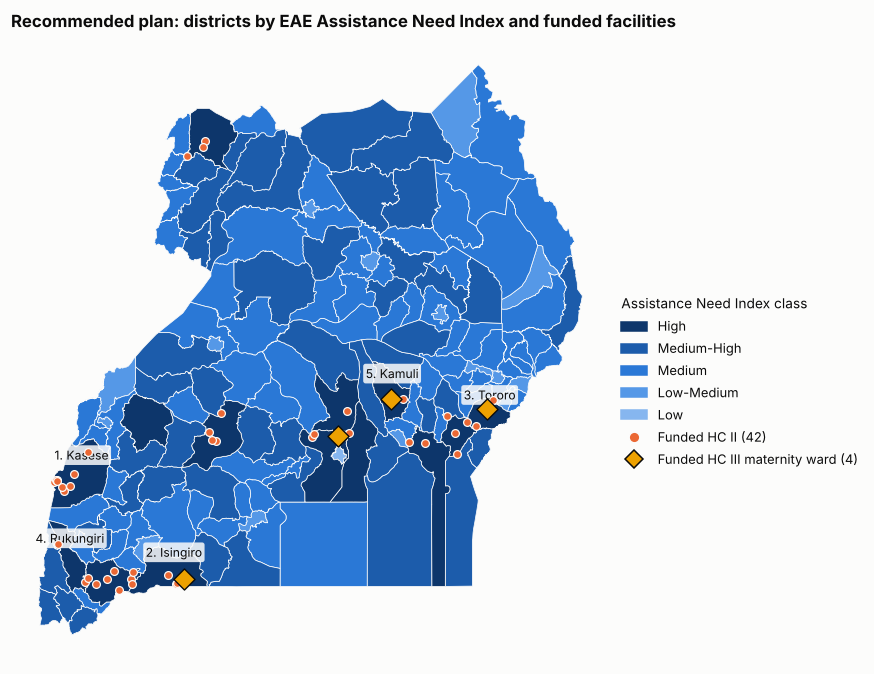

In [25]:
fig, ax = plt.subplots(figsize=(9.2, 7.4))
classes_map = districts.merge(ranking[["district", "class"]], on="district", how="left")
for label, colour in zip(CLASS_LABELS + [None], CLASS_COLOURS + ["#ecebe7"]):
    sub = classes_map[classes_map["class"].isna()] if label is None else classes_map[classes_map["class"] == label]
    if not sub.empty:
        sub.plot(ax=ax, color=colour, edgecolor=SURFACE, linewidth=0.5)
pts = plan.to_crs(3857)
mat_pts = pts["LEVEL"].isin(MATERNITY_LEVELS)
ax.scatter(pts.geometry.x[~mat_pts], pts.geometry.y[~mat_pts], s=26, marker="o", c=ORANGE, edgecolors=SURFACE,
           linewidths=0.8, zorder=4)
ax.scatter(pts.geometry.x[mat_pts], pts.geometry.y[mat_pts], s=95, marker="D", c=YELLOW, edgecolors=INK,
           linewidths=0.9, zorder=5)
for _, r in ranking.head(5).iterrows():
    c = districts.loc[districts["district"] == r["district"]].geometry.representative_point().iloc[0]
    ax.annotate(f"{r['rank']}. {r['district']}", (c.x, c.y), fontsize=8, color=INK, ha="center",
                xytext=(0, 9), textcoords="offset points",
                bbox=dict(boxstyle="round,pad=0.2", fc=SURFACE, ec="none", alpha=0.85))
handles = [Patch(color=c, label=l) for l, c in zip(CLASS_LABELS[::-1], CLASS_COLOURS[::-1])]
handles += [Line2D([], [], marker="o", ls="", color=ORANGE, markeredgecolor=SURFACE, markersize=7,
                   label=f"Funded HC II ({int((~mat_pts).sum())})"),
            Line2D([], [], marker="D", ls="", color=YELLOW, markeredgecolor=INK, markersize=8,
                   label=f"Funded HC III maternity ward ({int(mat_pts.sum())})")]
ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.45), fontsize=8.5,
          title="Assistance Need Index class", title_fontsize=9, alignment="left")
ax.set_axis_off()
ax.set_title("Recommended plan: districts by EAE Assistance Need Index and funded facilities", loc="left")
savefig(fig, "fig5_recommended_plan_map")
plt.show()

## 7. Sensitivity and trade-offs

Costs range from the Burkina Faso price (x0.65) to +50%. The four maternity wards are funded at every cost; only
the number of HC IIs moves. Need first is not monotonic: cheaper systems let it buy a big HC III early.

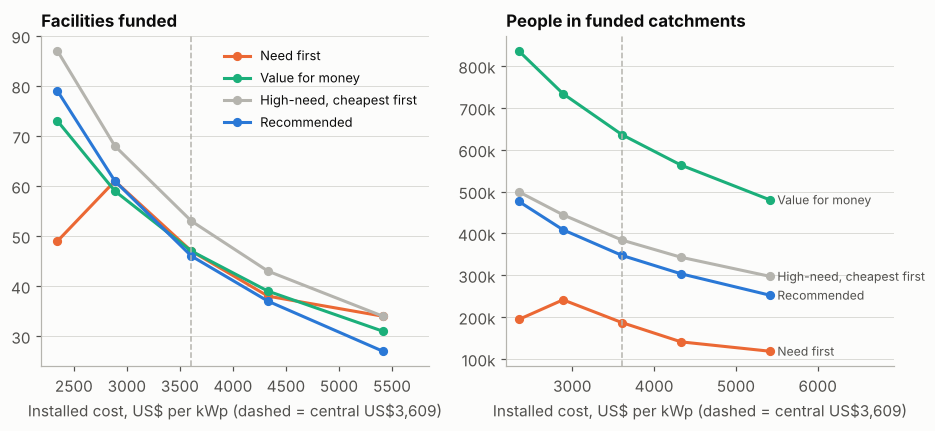

facilities                                                   people reached                                       
scenario        High-need, cheapest first Need first Recommended Value for money High-need, cheapest first Need first Recommended Value for money
cost multiplier                                                                                                                                  
0.65                                   87         49          79              73                    499485     194318      476534          836251
0.80                                   68         61          61              59                    444463     241294      408665          733927
1.00                                   53         47          46              47                    384013     186756      347341          635820
1.20                                   43         38          37              39                    342962     140790      303433          563135
1.50                                   34         34          27              31                    297517     118484      252446          480386

In [26]:
sens_rows = []
for m in COST_MULTIPLIERS:
    df_m = add_costs(eligible, mult=m)
    for s in SCENARIOS:
        f, r = allocate(df_m, s)
        sens_rows.append({"cost multiplier": m, "US$ per kWp": COST["usd_per_kwp"] * m, "scenario": s,
                          "facilities": len(f), "people reached": f["catchment_pop"].sum(),
                          "US$ per person": (BUDGET_USD - r) / f["catchment_pop"].sum(),
                          "unelectrified funded": int((f["group"] == "Unelectrified").sum())})
sensitivity = pd.DataFrame(sens_rows)
sensitivity.to_csv(TAB_DIR / "cost_sensitivity.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
for ax, col, title in zip(axes, ["facilities", "people reached"],
                          ["Facilities funded", "People in funded catchments"]):
    for s, colour in zip(SCENARIOS, [ORANGE, AQUA, NEUTRAL, BLUE]):
        d = sensitivity[sensitivity["scenario"] == s]
        ax.plot(d["US$ per kWp"], d[col], color=colour, lw=2, marker="o", ms=5, label=s)
        if col == "people reached":
            ax.annotate(s, (d["US$ per kWp"].iloc[-1], d[col].iloc[-1]), xytext=(5, 0), textcoords="offset points",
                        fontsize=8, color=INK2, va="center")
    ax.axvline(COST["usd_per_kwp"], color=NEUTRAL, lw=1, ls="--")
    ax.set_title(title, loc="left")
    ax.set_xlabel(r"Installed cost, US\$ per kWp (dashed = central US\$3,609)")
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
    ax.set_xlim(right=COST["usd_per_kwp"] * 1.5 * 1.28)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e3:,.0f}k"))
axes[0].legend(loc="upper right", fontsize=8.5)
axes[0].set_xlim(right=COST["usd_per_kwp"] * 1.5 * 1.08)
savefig(fig, "fig6_cost_sensitivity")
plt.show()
sensitivity.pivot(index="cost multiplier", columns="scenario", values=["facilities", "people reached"])

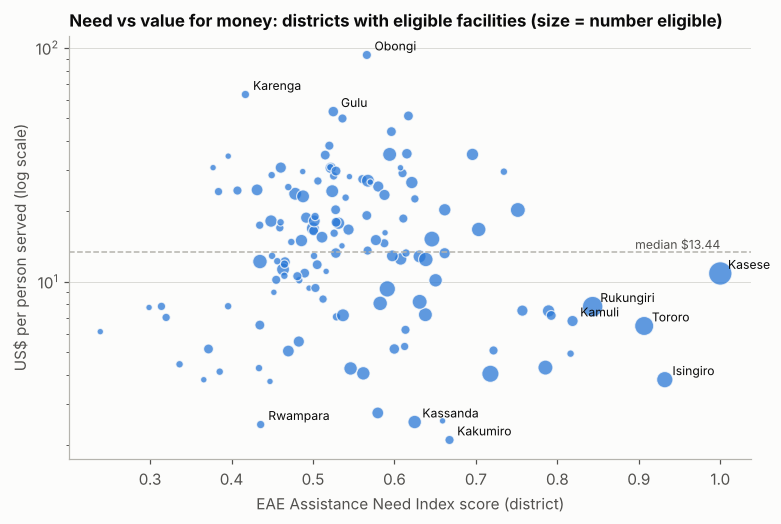

Correlation (Spearman) between ANI score and US$ per person: -0.04


In [27]:
# need (ANI score) vs cost per person of the eligible facilities, by district
dist_vfm = (eligible.groupby(["district", "class"])
            .agg(eligible=("FACILITY_N", "size"), cost=("total_cost", "sum"), people=("catchment_pop", "sum"))
            .reset_index())
dist_vfm["usd_per_person"] = dist_vfm["cost"] / dist_vfm["people"]
dist_vfm = dist_vfm.merge(ranking[["district", "score", "rank"]], on="district")
dist_vfm.to_csv(TAB_DIR / "need_vs_value_for_money.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(dist_vfm["score"], dist_vfm["usd_per_person"], s=12 + dist_vfm["eligible"] * 6, c=BLUE, alpha=0.75,
           edgecolors=SURFACE, linewidths=0.8)
med_cost = dist_vfm["usd_per_person"].median()
ax.axhline(med_cost, color=NEUTRAL, lw=1, ls="--")
ax.text(1.0, med_cost, f" median ${med_cost:.2f}", va="bottom", ha="right", fontsize=8, color=INK2)
lab = pd.concat([dist_vfm.nsmallest(5, "rank"), dist_vfm.nsmallest(3, "usd_per_person"),
                 dist_vfm.nlargest(3, "usd_per_person")]).drop_duplicates("district")
for _, r in lab.iterrows():
    ax.annotate(r["district"], (r["score"], r["usd_per_person"]), xytext=(5, 3), textcoords="offset points",
                fontsize=8, color=INK)
ax.set_yscale("log")
ax.set_xlabel("EAE Assistance Need Index score (district)")
ax.set_ylabel("US$ per person served (log scale)")
ax.set_title("Need vs value for money: districts with eligible facilities (size = number eligible)", loc="left")
ax.yaxis.grid(True, which="major")
ax.set_axisbelow(True)
savefig(fig, "fig7_need_vs_value_for_money")
plt.show()
print("Correlation (Spearman) between ANI score and US$ per person:",
      round(dist_vfm[["score", "usd_per_person"]].corr(method="spearman").iloc[0, 1], 2))

**Takeaway:** across districts, need and cost per person are unrelated (rank correlation about 0). So need picks
the districts and cost picks the facilities.

In [28]:
# grid what-if: if UEDCL connects the sites next to a line, how far does the MoH money go?
near_grid = eligible["dist_line_km"] <= 0
f_all, r_all = PLANS["Recommended"]
f_far, r_far = allocate(eligible[~near_grid], "Recommended")
priority = eligible["class"].isin(TOP_CLASSES)
grid_whatif = pd.DataFrame({
    "Recommended plan": {
        "facilities solarised with MoH money": len(f_all),
        "people reached with MoH money": f_all["catchment_pop"].sum(),
        "near-grid eligible facilities in High-class districts, referred to UEDCL": 0},
    "Near-grid facilities referred to UEDCL": {
        "facilities solarised with MoH money": len(f_far),
        "people reached with MoH money": f_far["catchment_pop"].sum(),
        "near-grid eligible facilities in High-class districts, referred to UEDCL": int((near_grid & priority).sum())},
})
print(f"Eligible facilities in the same 1 km cell as a distribution line: {near_grid.sum()} of {len(eligible)} "
      f"({(near_grid & priority).sum()} of {priority.sum()} in High-class districts)")
grid_whatif.to_csv(TAB_DIR / "grid_whatif.csv")
grid_whatif

Eligible facilities in the same 1 km cell as a distribution line: 480 of 853 (110 of 189 in High-class districts)


,Recommended plan,Near-grid facilities referred to UEDCL
facilities solarised with MoH money,46,61
people reached with MoH money,347341,211971
"near-grid eligible facilities in High-class districts, referred to UEDCL",0,110


## 8. Limitations and data checks

In [29]:
checks = pd.Series({
    "Facilities with unknown electrification status": int((fac["ELECTRIFIC"] == "Data unavailable").sum()),
    "Facilities with no WRI demand estimate (hospitals, clinics, RRH, NRH, SC)": int((fac["kwh_day"].fillna(0) <= 0).sum()),
    "Facility district attribute differs from EAE district (new districts since)": f"{(fac['DISTRICT'].str.lower() != fac['district'].str.lower()).mean():.0%}",
    "Unelectrified facilities within 1 km of an 11/33 kV line": f"{(unel['dist_line_km'] <= 1).mean():.0%}",
    "Unelectrified facilities in cells with no Relative Wealth Index (dropped by EAE)": int(unel["rwi"].isna().sum()),
    "Eligible facilities counted in their district's EAE score": f"{(eligible['pix'].map(lambda p: INDEX_CELLS[MAIN_INDEX][p] > 0 if p >= 0 else False)).mean():.0%}",
    "Health facility data content date": manifest.loc[manifest["category"] == "health", "content_date"].iloc[0],
    "Distribution lines content date": manifest.loc[manifest["category"] == "distribution", "content_date"].iloc[0],
    "Off-grid HC III/IV with unknown existing system size": int(((fac["ELECTRIFIC"] == "Off-grid") & fac["LEVEL"].isin(UPGRADE_LEVELS)).sum()),
    "Lowest GHI at a funded site (kWh/m2/yr)": round(float(plan["ghi"].min()), 0),
})
checks.to_csv(TAB_DIR / "data_checks.csv", header=["value"])
checks.to_frame("value")

,value
Facilities with unknown electrification status,130
"Facilities with no WRI demand estimate (hospitals, clinics, RRH, NRH, SC)",514
Facility district attribute differs from EAE district (new districts since),15%
Unelectrified facilities within 1 km of an 11/33 kV line,68%
Unelectrified facilities in cells with no Relative Wealth Index (dropped by EAE),23
Eligible facilities counted in their district's EAE score,92%
Health facility data content date,2023
Distribution lines content date,2024
Off-grid HC III/IV with unknown existing system size,410
Lowest GHI at a funded site (kWh/m2/yr),"1,560.00"


- Demand is modelled, not metered: audit each site before buying.
- Status may be stale (2023 facility data, 2024 lines); many "unelectrified" sites sit next to a line.
- EAE maps only 11/33 kV lines; cheap connections depend on low-voltage poles it does not show.
- "People reached" is catchment population, not patients.
- EAE's district score rewards size (it counts all facilities).
- Costs rest on two projects; existing solar at off-grid HC IIIs is unknown; battery replacement (~10 years) is
  outside the reserve.

## 9. Key numbers

In [30]:
rec = scenario_summary["Recommended"]
key_numbers = {
    "budget_usd": BUDGET_USD,
    "facilities_total": len(fac),
    "facilities_unelectrified": int((fac["ELECTRIFIC"] == "No").sum()),
    "facilities_off_grid": int((fac["ELECTRIFIC"] == "Off-grid").sum()),
    "facilities_status_unknown": int((fac["ELECTRIFIC"] == "Data unavailable").sum()),
    "unelectrified_catchment_pop": float(unel["catchment_pop"].sum()),
    "unelectrified_share_within_1km_of_line": float((unel["dist_line_km"] <= 1).mean()),
    "eligible_facilities": len(eligible),
    "eligible_total_cost_usd": float(eligible["total_cost"].sum()),
    "usd_per_kwp": COST["usd_per_kwp"],
    "cost_hc2_2bed_usd": float(unit_costs.query("LEVEL == 'HC II' and beds == 2")["total_cost"].iloc[0]),
    "cost_hc2_3bed_usd": float(unit_costs.query("LEVEL == 'HC II' and beds == 3")["total_cost"].iloc[0]),
    "cost_hc3_8bed_usd": float(unit_costs.query("LEVEL == 'HC III' and beds == 8")["total_cost"].iloc[0]),
    "top5_districts_ani": ranking["district"].head(5).to_list(),
    "top5_scores": [round(float(s), 3) for s in ranking["score"].head(5)],
    "recommended": {k: (float(v) if isinstance(v, (int, float, np.number)) else v) for k, v in rec.items()},
    "scenarios": {s: {k: (float(v) if isinstance(v, (int, float, np.number)) else v)
                      for k, v in scenario_summary[s].items()} for s in SCENARIOS},
}
(TAB_DIR / "key_numbers.json").write_text(json.dumps(key_numbers, indent=2))
print(json.dumps(key_numbers, indent=2))

{
  "budget_usd": 1000000,
  "facilities_total": 4938,
  "facilities_unelectrified": 582,
  "facilities_off_grid": 1553,
  "facilities_status_unknown": 130,
  "unelectrified_catchment_pop": 2475784.0,
  "unelectrified_share_within_1km_of_line": 0.6821305841924399,
  "eligible_facilities": 853,
  "eligible_total_cost_usd": 64190643.73477218,
  "usd_per_kwp": 3608.847583643123,
  "cost_hc2_2bed_usd": 14824.073530323953,
  "cost_hc2_3bed_usd": 21755.04060159321,
  "cost_hc3_8bed_usd": 47518.99531895912,
  "top5_districts_ani": [
    "Kasese",
    "Isingiro",
    "Tororo",
    "Rukungiri",
    "Kamuli"
  ],
  "top5_scores": [
    1.0,
    0.932,
    0.907,
    0.843,
    0.819
  ],
  "recommended": {
    "facilities funded": 46.0,
    "of which unelectrified": 46.0,
    "of which under-electrified": 0.0,
    "HC II / HC III / HC IV": "42/4/0",
    "maternity wards powered": 4.0,
    "people reached": 347341.0,
    "US$ per person": 2.8585517212262395,
    "districts reached": 13.0,
    "fu

## 10. Recommendations

In [31]:
from IPython.display import Markdown

big_mat = eligible[(eligible["group"] == "Unelectrified") & eligible["LEVEL"].isin(MATERNITY_LEVELS)
                   & (eligible["total_cost"] > MATERNITY_COST_CAP) & eligible["class"].isin(TOP_CLASSES)]
og8 = eligible[(eligible["group"] == "Under-electrified") & (eligible["beds"] == 8) & eligible["class"].isin(TOP_CLASSES)]
plan_near_line = int((plan["dist_line_km"] <= 0).sum())
mat_names = ", ".join(plan.loc[plan["LEVEL"].isin(MATERNITY_LEVELS), "district"])
big_list = "; ".join(f"{r.district} ({int(r.beds)} beds, ${r.total_cost / 1e3:,.0f}k, "
                     f"{'next to a line' if r.dist_line_km <= 0 else f'{r.dist_line_km:.0f} km from a line'})"
                     for r in big_mat.itertuples())
top5_text = ", ".join(ranking["district"].head(5))
recs_md = f"""
1. **Fund now:** solar PV and batteries for {rec['facilities funded']} facilities with no electricity in
   {rec['districts reached']} High-need districts, starting with {top5_text}: the
   {rec['maternity wards powered']} HC III maternity wards that have no power ({mat_names}), then
   {rec['facilities funded'] - rec['maternity wards powered']} HC IIs. Cost ${(rec['equipment + installation'] + rec['delivery overhead']) / 1e3:,.0f}k;
   about {rec['people reached'] / 1e3:,.0f},000 people live in their catchments.
2. **Keep the systems working:** ring-fence ${rec['maintenance reserve'] / 1e3:,.0f}k for five years of maintenance
   and use remote monitoring where there is phone signal.
3. **Check before buying:** confirm each site still has no power and size it from an energy audit;
   {plan_near_line} of the {len(plan)} funded sites are in the same 1 km square as a distribution line.
4. **Ask UEDCL to connect the facilities next to the grid:** {int((near_grid & priority).sum())} eligible facilities in
   High-need districts are in the same 1 km square as a line. A grid connection is far cheaper than solar if a
   low-voltage pole is close.
5. **Plan a second phase for maternity:** the larger unelectrified maternity units in High-need districts ({big_list})
   are too expensive for this budget and should be connected to the grid or funded next. Upgrading the
   {len(og8)} off-grid 8-bed HC IIIs in High-need districts would cost about ${og8['total_cost'].sum() / 1e6:,.1f} million.
6. **Budget for batteries:** replacement after about 10 years is not covered by the reserve.
7. **Collect better data:** up-to-date electrification status from district health offices, the low-voltage network,
   the size of existing solar at off-grid HC IIIs, deliveries per month, and recent Ugandan tender prices.
"""
(TAB_DIR / "recommendations.md").write_text(recs_md)
Markdown(recs_md)


1. **Fund now:** solar PV and batteries for 46 facilities with no electricity in
   13 High-need districts, starting with Kasese, Isingiro, Tororo, Rukungiri, Kamuli: the
   4 HC III maternity wards that have no power (Isingiro, Tororo, Wakiso, Kamuli), then
   42 HC IIs. Cost $869k;
   about 347,000 people live in their catchments.
2. **Keep the systems working:** ring-fence $124k for five years of maintenance
   and use remote monitoring where there is phone signal.
3. **Check before buying:** confirm each site still has no power and size it from an energy audit;
   35 of the 46 funded sites are in the same 1 km square as a distribution line.
4. **Ask UEDCL to connect the facilities next to the grid:** 110 eligible facilities in
   High-need districts are in the same 1 km square as a line. A grid connection is far cheaper than solar if a
   low-voltage pole is close.
5. **Plan a second phase for maternity:** the larger unelectrified maternity units in High-need districts (Mayuge (24 beds, $466k, next to a line); Kyenjojo (20 beds, $409k, 6 km from a line))
   are too expensive for this budget and should be connected to the grid or funded next. Upgrading the
   17 off-grid 8-bed HC IIIs in High-need districts would cost about $0.8 million.
6. **Budget for batteries:** replacement after about 10 years is not covered by the reserve.
7. **Collect better data:** up-to-date electrification status from district health offices, the low-voltage network,
   the size of existing solar at off-grid HC IIIs, deliveries per month, and recent Ugandan tender prices.
